# NYC Taxi — Öğrenci 3

Saat, gün, biniş bölgesi ve ödeme türü dağılımlarını 17.210.961 temiz yolculuk üzerinden inceleyeceğiz. PySpark sorguları `src/aggregate_trips.py` dosyasında. Bu notebook doğrulanmış altı küçük sonuç tablosunu okur ve yedi grafiği üretir.

Sonuçları yeniden üretmek için Spark ortamını hazırladıktan sonra proje kökünde `python -m src.aggregate_trips --analysis all --export` çalıştır.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.axisbelow": True, "grid.color": "#e1e0d9",
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

def tr_int(value):
    return f"{value:,.0f}".replace(",", ".")

results = root / "reports" / "results"
figures = root / "reports" / "figures"

hour = pd.read_csv(results / "s3_hour.csv")
day = pd.read_csv(results / "s3_day.csv", parse_dates=["pickup_date"])
zone = pd.read_csv(results / "s3_zone.csv")
payment = pd.read_csv(results / "s3_payment.csv")

def show_figure(fig, filename):
    fig.savefig(figures / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Saat · En yoğun biniş saati ne zaman?

Spark `pickup_hour` sütununa göre kayıtları sayar. Grafikte saatleri 0–23 sırasına koyuyoruz. 18.00–18.59 arasında **1.150.635** yolculuk başlamış. Saatler New York yerel saatidir.

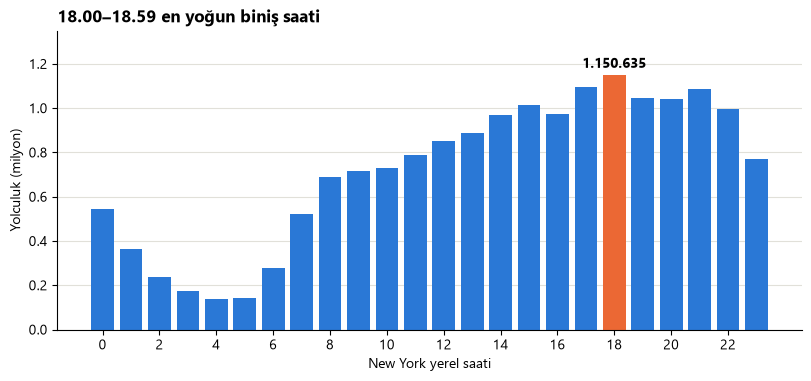

In [2]:
hourly = hour.sort_values("pickup_hour")
peak = hourly.loc[hourly.trip_count.idxmax()]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
colors = [ORANGE if value == peak.pickup_hour else BLUE for value in hourly.pickup_hour]
ax.bar(hourly.pickup_hour, hourly.trip_count / 1_000_000, color=colors)
ax.set(title=f"{int(peak.pickup_hour):02d}.00–{int(peak.pickup_hour):02d}.59 en yoğun biniş saati", xlabel="New York yerel saati",
       ylabel="Yolculuk (milyon)", ylim=(0, 1.35))
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="y")
ax.annotate(tr_int(peak.trip_count), (peak.pickup_hour, peak.trip_count / 1_000_000),
            xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold")
show_figure(fig, "11_s3_hour.png")

## Gün · Hangi tarihte en çok yolculuk başladı?

`to_date` biniş zamanını takvim tarihine dönüştürür. Günlük sayılar 151 tarihi kapsar. **25 Nisan 2026** günü **153.232** yolculukla zirvede. Grafik zirvenin tarihini gösterir. Zirvenin nedenini belirlemek için ayrıca olay ve hava durumu verisi gerekir.

En düşük değer 23 Şubat'ta 22.513. İki uç günün nedenini bu özet tek başına açıklayamaz.

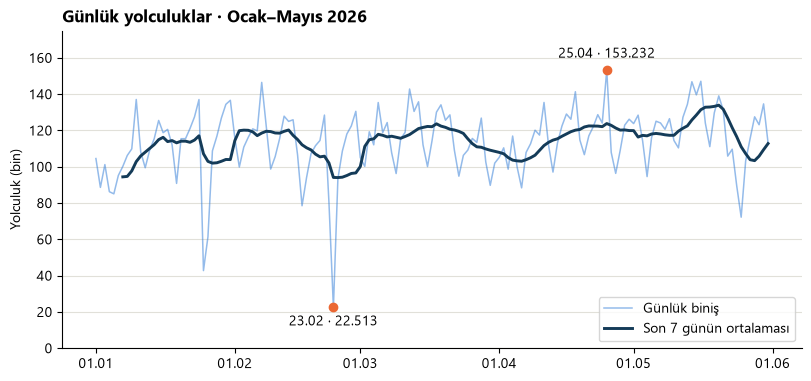

25 Nisan: 153.232; 18 Nisan: 141.356; değişim %8.4


In [3]:
peak_day = day.loc[day.trip_count.idxmax()]
low_day = day.loc[day.trip_count.idxmin()]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
ax.plot(day.pickup_date, day.trip_count / 1_000, color=BLUE, alpha=0.5, linewidth=1.1, label="Günlük biniş")
ax.plot(day.pickup_date, day.trailing_7d_avg / 1_000, color="#143b58",
        linewidth=2.1, label="Son 7 günün ortalaması")
ax.legend(loc="lower right")
for row, offset in ((peak_day, 9), (low_day, -13)):
    pos = row.pickup_date, row.trip_count / 1_000
    ax.scatter(*pos, color=ORANGE, zorder=3)
    ax.annotate(f"{row.pickup_date:%d.%m} · {tr_int(row.trip_count)}", pos,
                xytext=(0, offset), textcoords="offset points", ha="center")
ax.set(title="Günlük yolculuklar · Ocak–Mayıs 2026", ylabel="Yolculuk (bin)", ylim=(0, 175))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.grid(axis="y")
show_figure(fig, "12_s3_day.png")
print(f"25 Nisan: {tr_int(peak_day.trip_count)}; 18 Nisan: {tr_int(peak_day.previous_week_trips)}; değişim %{peak_day.week_change_pct:.1f}")

Koyu çizgi, bugünün ve önceki altı günün ortalamasını gösterir. İlk altı günde yedi günlük pencere tamamlanmaz. Haftalık değişim ayrı hesaplanır. `lag(7)` ile ortalamaları değil, 25 Nisan'ın ve 18 Nisan'ın **günlük biniş sayılarını** karşılaştırırız.

### Haftanın günü

Bir pazartesi ile bir cumartesiyi karşılaştırmak için her grubun toplamını gruptaki gün sayısına bölüyoruz. Böylece ay sınırlarından dolayı bazı hafta günlerinin daha sık görülmesi karşılaştırmayı çarpıtmaz.

In [4]:
weekdays = ["Pazartesi", "Salı", "Çarşamba", "Perşembe", "Cuma", "Cumartesi", "Pazar"]
weekly = day.groupby(day.pickup_date.dt.dayofweek).trip_count.agg(
    gun_sayisi="size", gunluk_ortalama="mean"
)
weekly.index = [weekdays[i] for i in weekly.index]
weekly.round({"gunluk_ortalama": 0})

,gun_sayisi,gunluk_ortalama
Pazartesi,21,90208.0
Salı,21,110124.0
Çarşamba,21,117404.0
Perşembe,22,124311.0
Cuma,22,119498.0
Cumartesi,22,130586.0
Pazar,22,104629.0


### Hafta günü × saat

Saatlik zirve haftanın her gününde aynı mı? PySpark yolculukları `pickup_dow` ve `pickup_hour` ile 168 gruba ayırır. Her hücreyi ilgili hafta gününün veri dönemindeki tekrar sayısına bölüyoruz. Örneğin bir cumartesi saat 18 için hücre, 22 cumartesinin o saatteki ortalamasını gösterir.

Gün ve saati birlikte gösterme yaklaşımı benzer ölçekte bir NYC Yellow Taxi analizinden esinlendi. [Loayib — NYC Taxi Analysis, Demand Analysis](https://github.com/Loayib/NYC_Taxi_Analysis)

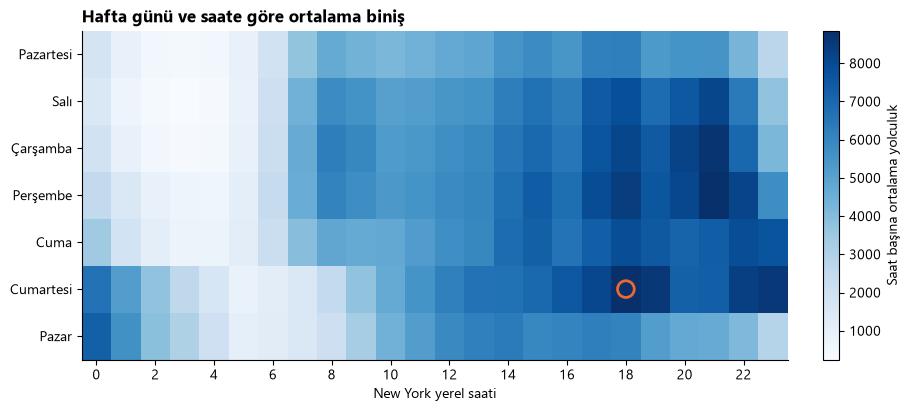

Hafta içi: Perşembe 21.00–21.59 · ortalama 8.830 biniş
Hafta sonu: Cumartesi 18.00–18.59 · ortalama 8.853 biniş


In [5]:
pattern = pd.read_csv(results / "s3_pattern.csv")
assert len(pattern) == 168 and pattern.trip_count.sum() == day.trip_count.sum()
# Spark: Pazar=1, Python: Pazartesi=0.
pattern["weekday"] = (pattern.pickup_dow + 5) % 7
day_counts = day.pickup_date.dt.dayofweek.value_counts()
pattern["mean_trips"] = pattern.trip_count / pattern.weekday.map(day_counts)
matrix = pattern.pivot(index="weekday", columns="pickup_hour", values="mean_trips")
peak_weekday, peak_hour = matrix.stack().idxmax()

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
image = ax.imshow(matrix, aspect="auto", cmap="Blues")
ax.set(title="Hafta günü ve saate göre ortalama biniş", xlabel="New York yerel saati")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(7), weekdays)
ax.scatter(peak_hour, peak_weekday, s=145, facecolors="none", edgecolors=ORANGE, linewidths=2)
fig.colorbar(image, ax=ax, label="Saat başına ortalama yolculuk")
show_figure(fig, "15_s3_weekday_hour.png")
for name, subset in [("Hafta içi", matrix.iloc[:5]), ("Hafta sonu", matrix.iloc[5:])]:
    weekday, hour_index = subset.stack().idxmax()
    print(f"{name}: {weekdays[weekday]} {hour_index:02d}.00–{hour_index:02d}.59 · ortalama {tr_int(matrix.loc[weekday, hour_index])} biniş")


## Bölge · En çok biniş nerede?

Önce `PULocationID` ile sayıyoruz, sonra TLC bölge tablosundan adları bir sol birleştirmeyle ekliyoruz. 260 bölge grubu içinde **Upper East Side South**, **815.297** binişle birinci. Grafik ilk 10 bölgeyi, CSV ise 260 grubun tamamını içerir. Sonuçlar temizleme sonrası veri kümesini temsil eder.

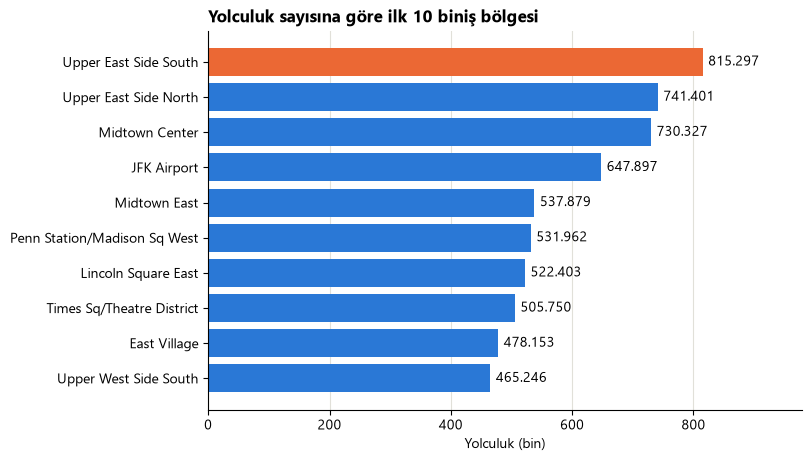

In [6]:
top_zones = zone.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
colors = [BLUE] * (len(top_zones) - 1) + [ORANGE]
bars = ax.barh(top_zones.pickup_zone, top_zones.trip_count / 1_000, color=colors)
ax.bar_label(bars, labels=[tr_int(value) for value in top_zones.trip_count], padding=4)
ax.set_xlim(0, top_zones.trip_count.max() / 1_000 * 1.2)
ax.grid(axis="x")
ax.set(title="Yolculuk sayısına göre ilk 10 biniş bölgesi", xlabel="Yolculuk (bin)")
show_figure(fig, "13_s3_zone.png")

### Upper East Side South nerede?

Upper East Side, Manhattan'da Central Park'ın doğusundaki mahalledir. Haritadaki turuncu sınır, bu mahallenin **Upper East Side South** adlı TLC taksi bölgesini gösterir. Renkler bölgelerin temiz veri kümesindeki toplam biniş sayısını gösterir. GeoJSON sınır dosyasında bire bir eşleşmeyen 57 (Corona, 212 biniş) ve 105 (Governor’s / Ellis / Liberty Island, 6 biniş) kodlu toplam 218 yolculuk haritada yer almaz; ancak tablolarda ve 17.210.961 genel toplamında korunur.

Sınırlar [NYC Open Data — NYC Taxi Zones](https://catalog.data.gov/dataset/nyc-taxi-zones) kaynağından, sayımlar kendi PySpark çıktımızdan geliyor. Haritayı yeniden çizmek için kaynağın GeoJSON dosyasını `data/raw/taxi_zones.geojson` olarak kaydet.

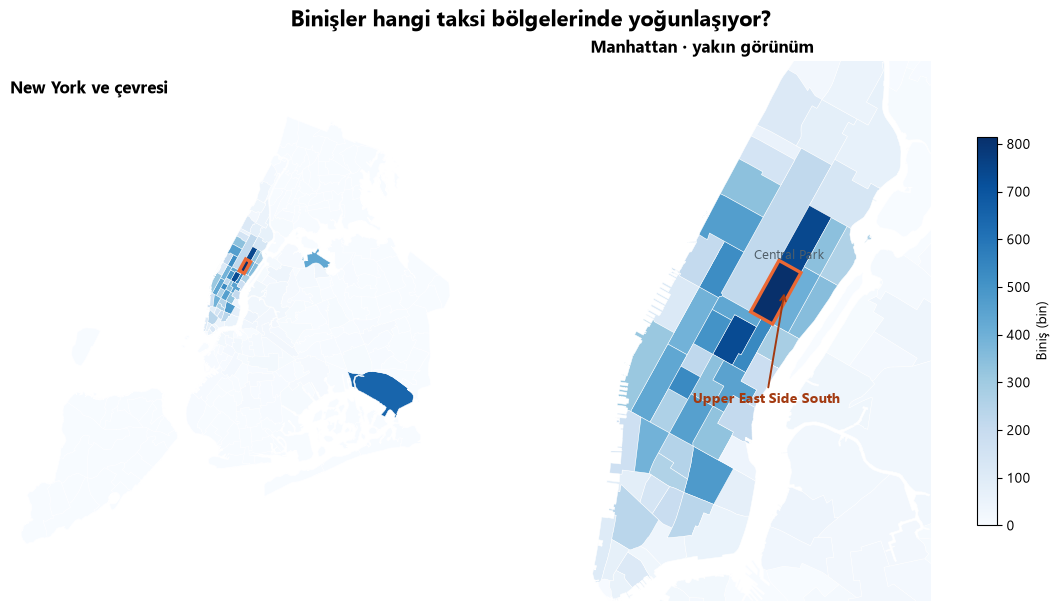

Haritada gösterilen: 17.210.743 / 17.210.961 yolculuk


In [7]:
import json
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
from IPython.display import Image, display

geometry_file = root / "data" / "raw" / "taxi_zones.geojson"
map_name = "16_s3_pickup_map.png"

if geometry_file.exists():
    shapes = json.loads(geometry_file.read_text(encoding="utf-8"))["features"]
    counts = zone.set_index("PULocationID").trip_count
    peak_id = int(counts.idxmax())
    norm = Normalize(0, counts.max() / 1_000)
    shapes_by_id = {}
    for feature in shapes:
        zone_id = int(feature["properties"]["locationid"])
        geometry = feature["geometry"]
        polygons = geometry["coordinates"]
        if geometry["type"] == "Polygon":
            polygons = [polygons]
        shapes_by_id.setdefault(zone_id, []).extend(polygon[0] for polygon in polygons)

    assert peak_id in shapes_by_id
    mapped = int(counts.reindex(shapes_by_id, fill_value=0).sum())
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 6), layout="constrained")
    for ax in axes:
        patches, values = [], []
        for zone_id, outlines in shapes_by_id.items():
            for outline in outlines:
                patches.append(Polygon(outline, closed=True))
                values.append(counts.get(zone_id, 0) / 1_000)
        collection = PatchCollection(patches, cmap="Blues", norm=norm,
                                     edgecolor="#ffffff", linewidth=0.35)
        collection.set_array(values)
        ax.add_collection(collection)
        for outline in shapes_by_id[peak_id]:
            ax.add_patch(Polygon(outline, closed=True, fill=False, edgecolor=ORANGE, linewidth=2.4))
        ax.set_aspect(1.32)
        ax.set_axis_off()

    axes[0].set(title="New York ve çevresi", xlim=(-74.27, -73.68), ylim=(40.48, 40.93))
    axes[1].set(title="Manhattan · yakın görünüm", xlim=(-74.02, -73.92), ylim=(40.70, 40.82))
    axes[1].annotate("Central Park", (-73.972, 40.776), color="#515f69", fontsize=9)
    axes[1].annotate("Upper East Side South", xy=(-73.963, 40.769), xytext=(-73.990, 40.744),
                     arrowprops={"arrowstyle": "->", "color": "#a33a11", "lw": 1.4},
                     color="#a33a11", fontsize=10, fontweight="bold")
    fig.suptitle("Binişler hangi taksi bölgelerinde yoğunlaşıyor?", fontsize=16, fontweight="bold")
    fig.colorbar(collection, ax=axes, shrink=0.72, label="Biniş (bin)")
    show_figure(fig, map_name)
    print(f"Haritada gösterilen: {tr_int(mapped)} / {tr_int(counts.sum())} yolculuk")
else:
    display(Image(filename=str(figures / map_name)))


### Her 10 binişin yaklaşık 8'i kaç bölgeden geliyor?

Her ilçede bölgeleri en çok biniş alandan başlayarak sıralıyoruz. Sayıları biriktirip ilçe toplamının en az %80'ine ilk ulaştığımız sırayı buluyoruz. Yüzde tam 80 olmak zorunda değil. Bölgelerin sayısı ilçeden ilçeye değiştiği için sonucu, o ilçede biniş kaydı olan bölgelerin yüzdesiyle birlikte gösteriyoruz. Bu, binişlerin nerede yoğunlaştığını ölçer. Farkın nedenini veya kişi başına kullanımı belirlemez.

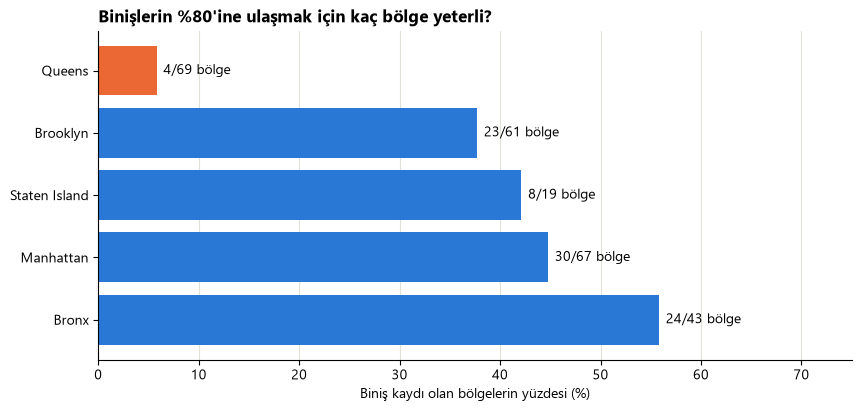

,borough,zones_to_80pct,observed_zones,cumulative_pct
0,Queens,4,69,80.88
1,Brooklyn,23,61,80.56
2,Staten Island,8,19,84.58
3,Manhattan,30,67,81.06
4,Bronx,24,43,81.09


In [8]:
concentration = pd.read_csv(results / "s3_zone_concentration.csv")
view = concentration.sort_values("observed_zones_pct", ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.0), layout="constrained")
bars = ax.barh(view.borough, view.observed_zones_pct, color=[ORANGE if x == "Queens" else BLUE for x in view.borough])
labels = [f"{r.zones_to_80pct}/{r.observed_zones} bölge" for r in view.itertuples()]
ax.bar_label(bars, labels=labels, padding=5)
ax.set(title="Binişlerin %80'ine ulaşmak için kaç bölge yeterli?",
       xlabel="Biniş kaydı olan bölgelerin yüzdesi (%)", xlim=(0, 75))
ax.grid(axis="x")
show_figure(fig, "17_s3_zone_concentration.png")
concentration[["borough", "zones_to_80pct", "observed_zones", "cumulative_pct"]].round(2)

## Ödeme · Kayıtlar ödeme türlerine nasıl dağılıyor?

Spark önce ödeme kodlarına göre sayar. Her grubun sayısı toplam yolculuk sayısına bölünür. En yaygın kategori **kredi kartı (%64,96)**. Flex Fare **%25,45** ile ayrı bir kategori.

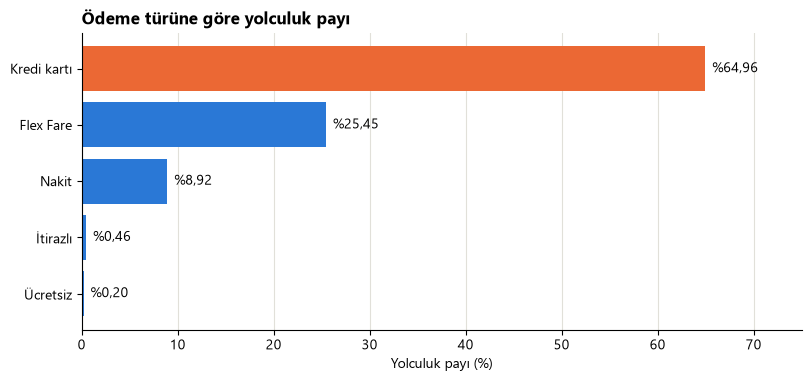

In [9]:
labels = {
    "Credit card": "Kredi kartı", "Flex Fare": "Flex Fare", "Cash": "Nakit",
    "No charge": "Ücretsiz", "Dispute": "İtirazlı",
}
payment_plot = payment.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
bars = ax.barh(payment_plot.payment_label.map(labels), payment_plot.share_pct, color=[BLUE] * (len(payment_plot) - 1) + [ORANGE])
ax.bar_label(bars, labels=[f"%{share:.2f}".replace(".", ",") for share in payment_plot.share_pct], padding=5)
ax.set(title="Ödeme türüne göre yolculuk payı", xlabel="Yolculuk payı (%)", xlim=(0, 75))
ax.grid(axis="x")
show_figure(fig, "14_s3_payment.png")

### Ödeme tutarı ve kayıtlı bahşiş

Ortalama toplam tutar, veri setindeki `total_amount` alanının yolculuk başına ortalamasıdır. Tutar farkı ödeme yönteminin etkisini göstermez. Bahşiş oranı yalnızca temel ücreti pozitif ve kayıtlı bahşişi negatif olmayan kredi kartı yolculuklarından hesaplanır. Toplam kayıtlı bahşişi toplam temel ücrete bölüyoruz. Temel ücret `fare_amount`, yani taksimetre ücretidir. Nakit bahşişi bu oranla kıyaslamıyoruz.

In [10]:
payment[["payment_label", "trip_count", "share_pct", "mean_total_amount",
         "tip_eligible_trips", "weighted_tip_pct"]].round(2).fillna("—")

,payment_label,trip_count,share_pct,mean_total_amount,tip_eligible_trips,weighted_tip_pct
0,Credit card,11180868,64.96,29.05,11180868,23.5
1,Flex Fare,4380672,25.45,32.63,0,—
2,Cash,1535553,8.92,24.87,0,—
3,Dispute,79783,0.46,27.76,0,—
4,No charge,34085,0.20,23.93,0,—


## Kontrol

Her özetin toplamı temiz veriyle aynı olmalı. Ödeme paylarının yuvarlanmamış toplamı %100 olmalı. Sınıfta kontrol için herhangi bir tablodaki `trip_count` sütununu topla ve aşağıdaki değerle karşılaştır.

In [11]:
expected = 17_210_961
totals = pd.Series({name: frame.trip_count.sum() for name, frame in {
    "Saat": hour, "Gün": day, "Bölge": zone, "Ödeme": payment,
}.items()}, name="Toplam yolculuk")
assert totals.eq(expected).all()
assert abs(payment.share_pct.sum() - 100) < 1e-8
totals.to_frame()

,Toplam yolculuk
Saat,17210961
Gün,17210961
Bölge,17210961
Ödeme,17210961
